In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("Cafe_Sales.csv")
df

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2,4,Credit Card,Takeaway,08-09-2023
1,TXN_4977031,Cake,4,3,12,Cash,In-store,16-05-2023
2,TXN_4271903,Cookie,4,1,ERROR,Credit Card,In-store,19-07-2023
3,TXN_7034554,Salad,2,5,10,UNKNOWN,UNKNOWN,27-04-2023
4,TXN_3160411,Coffee,2,2,4,Digital Wallet,In-store,11-06-2023
...,...,...,...,...,...,...,...,...
9995,TXN_7672686,Coffee,2,2,4,NaN,UNKNOWN,30-08-2023
9996,TXN_9659401,NaN,3,NaN,3,Digital Wallet,NaN,02-06-2023
9997,TXN_5255387,Coffee,4,2,8,Digital Wallet,NaN,02-03-2023
9998,TXN_7695629,Cookie,3,NaN,3,Digital Wallet,NaN,02-12-2023


In [3]:
print("\nShape:")
print(df.shape)


Shape:
(10000, 8)


In [4]:
print("\nData types:")
print(df.dtypes)


Data types:
Transaction ID      object
Item                object
Quantity            object
Price Per Unit      object
Total Spent         object
Payment Method      object
Location            object
Transaction Date    object
dtype: object


In [5]:
df = df.replace("UNKNOWN", pd.NA)

num = ["Quantity", "Price Per Unit", "Total Spent"]

for c in num:
    df[c] = pd.to_numeric(df[c], errors="coerce")

In [6]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
Transaction ID         0
Item                 677
Quantity             479
Price Per Unit       533
Total Spent          502
Payment Method      2872
Location            3604
Transaction Date     320
dtype: int64


In [7]:
for c in num:
    df[c] = df[c].fillna(df[c].mean())

In [8]:
cat = ["Item", "Payment Method", "Location"]

for c in cat:
    df[c] = df[c].fillna(df[c].mode()[0])

df["Transaction Date"] = df["Transaction Date"].fillna(df["Transaction Date"].mode()[0]
)

In [9]:
print("\nmissing values after handling:")
print(df.isnull().sum())


missing values after handling:
Transaction ID      0
Item                0
Quantity            0
Price Per Unit      0
Total Spent         0
Payment Method      0
Location            0
Transaction Date    0
dtype: int64


In [10]:
print("\nStatistical Analysis:")

for c in num:
    print("\nColumn:", c)
    print("Mean:", df[c].mean())
    print("Median:", df[c].median())
    print("Mode:", df[c].mode()[0])
    print("Minimum:", df[c].min())
    print("Maximum:", df[c].max())
    print("Standard Deviation:", df[c].std())

print("\nDescriptive Statistics:")
print(df[num].describe())


Statistical Analysis:

Column: Quantity
Mean: 3.028463396702027
Median: 3.0
Mode: 5.0
Minimum: 1.0
Maximum: 5.0
Standard Deviation: 1.3846011533957254

Column: Price Per Unit
Mean: 2.949984155487483
Median: 3.0
Mode: 3.0
Minimum: 1.0
Maximum: 5.0
Standard Deviation: 1.2439097559350611

Column: Total Spent
Mean: 8.92435249526216
Median: 8.0
Mode: 6.0
Minimum: 1.0
Maximum: 25.0
Standard Deviation: 5.857112795893125

Descriptive Statistics:
           Quantity  Price Per Unit   Total Spent
count  10000.000000    10000.000000  10000.000000
mean       3.028463        2.949984      8.924352
std        1.384601        1.243910      5.857113
min        1.000000        1.000000      1.000000
25%        2.000000        2.000000      4.000000
50%        3.000000        3.000000      8.000000
75%        4.000000        4.000000     12.000000
max        5.000000        5.000000     25.000000


In [11]:
from sklearn.preprocessing import LabelEncoder, StandardScaler

In [12]:
encoder = LabelEncoder()

for c in cat:
    df[c] = encoder.fit_transform(df[c])


In [13]:
scaler = StandardScaler()

df[num] = scaler.fit_transform(df[num])


In [14]:
print("\nData after scaling:")
df


Data after scaling:


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,1,-0.742824,-0.763746,-8.407895e-01,1,2,08-09-2023
1,TXN_4977031,0,0.701708,0.040211,5.251395e-01,0,1,16-05-2023
2,TXN_4271903,2,0.701708,-1.567703,3.032972e-16,1,1,19-07-2023
3,TXN_7034554,5,-0.742824,1.648125,1.836573e-01,2,2,27-04-2023
4,TXN_3160411,1,-0.742824,-0.763746,-8.407895e-01,2,1,11-06-2023
...,...,...,...,...,...,...,...,...
9995,TXN_7672686,1,-0.742824,-0.763746,-8.407895e-01,2,2,30-08-2023
9996,TXN_9659401,4,-0.020558,0.000000,-1.011531e+00,2,2,02-06-2023
9997,TXN_5255387,1,0.701708,-0.763746,-1.578250e-01,2,2,02-03-2023
9998,TXN_7695629,2,-0.020558,0.000000,-1.011531e+00,2,2,02-12-2023


In [15]:
from sklearn.model_selection import train_test_split

In [16]:
X = df.drop(
    ["Total Spent", "Transaction ID", "Transaction Date"],
    axis=1
)

y = df["Total Spent"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [17]:
print("\nTraining data:")
print(X_train.shape)

print("\nTesting data:")
print(X_test.shape)


Training data:
(8000, 5)

Testing data:
(2000, 5)


In [18]:
import matplotlib.pyplot as plt

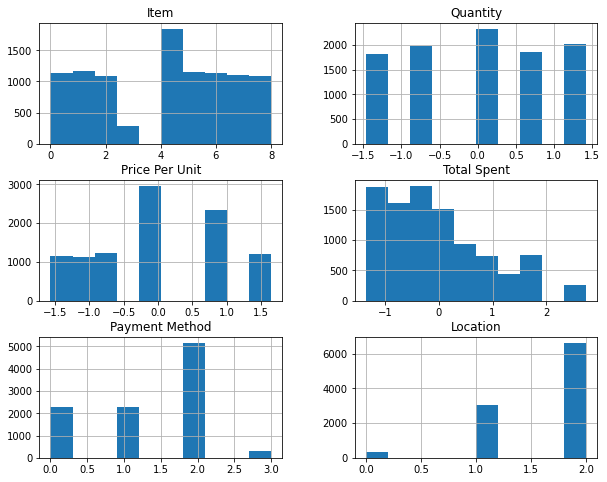

In [23]:
df.hist(figsize = (10,8))
plt.show()

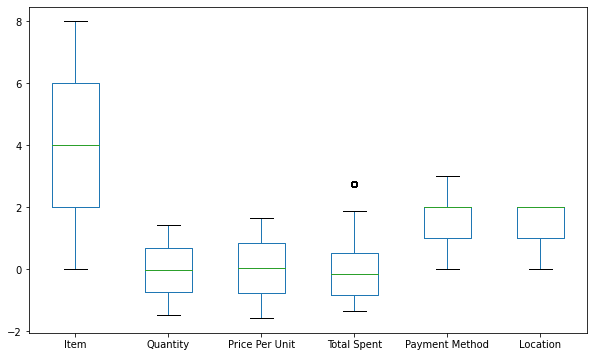

In [24]:
df.plot(kind="box", figsize=(10, 6))
plt.show()

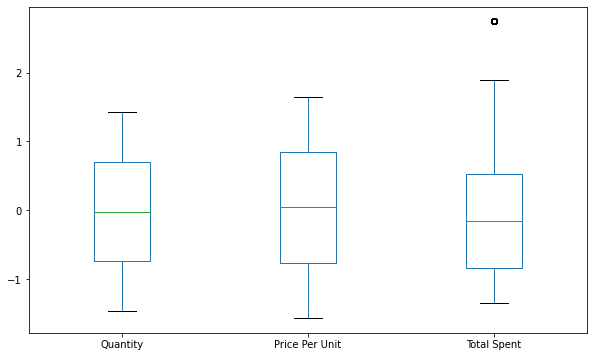

In [25]:
df[["Quantity", "Price Per Unit", "Total Spent"]].plot(kind="box", figsize=(10, 6))
plt.show()

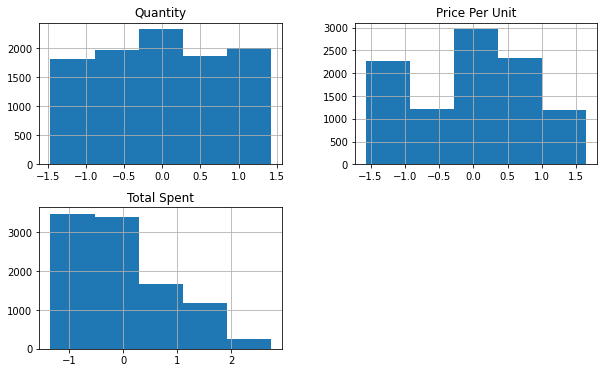

In [27]:
df[["Quantity", "Price Per Unit", "Total Spent"]].hist(figsize=(10, 6), bins=5)
plt.show()